[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_symmetries_and_integrability.ipynb)


# Dynamic Symmetries, Integrability, and Orbit Space Topology in Classical Central Fields

This notebook synthesizes the classical mechanics discussion on:
1. **D. M. Fradkin's 1967 Generalization** of the Laplace-Runge-Lenz (LRL) vector ($O_4$ symmetry) and conserved tensor ($SU_3$ symmetry) for *any* classical central potential.
1. **Distinction Between $O_4$ and $SU_3$ Symmetries**: Dimensionality, tensor representations, and algebraic structures.
1. **Complete Integrability vs. Superintegrability** in central force motion.
1. **Trajectory Quotient Space ($\mathcal{O} = Ph / \sim$) Topology** across chaotic, integrable, and superintegrable regimes.
1. **The Infinite-Dimensional Lie Algebra**: Mutual brackets, lack of new physical constants, and high-energy physics context.
1. **Embedding into the $\infty$-Dimensional Lie Algebra**: The Poisson algebra $(C^\infty(M), \{\cdot, \cdot\})$ as an infinite sea and subalgebra filtering by $H$.
1. **Observed Physics vs. Formal Algebraic Reflection**: Distinguishing physical observables from Poisson bracket artifacts.
1. **Quantum Mechanical Breakdown** of generalized dynamic symmetries.

---
## Fradkin's Generalization of the Laplace-Runge-Lenz Vector

In 1967, D. M. Fradkin (*Progress of Theoretical Physics*, Vol. 37, No. 5) demonstrated that **all** classical central potential problems (both relativistic and non-relativistic) inherently possess $O_4$ and $SU_3$ dynamic symmetries.

### The Unit Runge Vector $\hat{k}$
In any central potential $V(r)$, orbital angular momentum $\mathbf{L} = \mathbf{r} \times \mathbf{p}$ is conserved, restricting motion to a fixed 2D plane perpendicular to $\mathbf{L}$.

A unit vector $\hat{k}$ in the orbital plane can be expanded as:
$$\hat{k} = (\cos\theta)\hat{r} + (\sin\theta)\hat{r} \times \hat{L}$$

From the orbit equation for a general central potential:
$$\theta = \int^u \frac{L}{\sqrt{2m(E - V(1/u)) - L^2 u^2}} du, \quad u = \frac{1}{r}$$

Setting $\cos\theta = f(u, L^2, E)$ yields $\sin\theta = \frac{\partial f}{\partial u} \frac{\mathbf{r} \cdot \mathbf{p}}{L}$. In canonical variables $(\mathbf{r}, \mathbf{p})$:
$$\hat{k} = \left[f - u \frac{\partial f}{\partial u}\right]\hat{r} + L^{-2} \frac{\partial f}{\partial u} \frac{\mathbf{p}}{L}$$

### 1.2 $O_4$ and $SU_3$ Algebras
- **Generalized LRL Vector ($O_4$)**: $\mathbf{A} = \sqrt{P^2(E) - L^2} \,\hat{k}$, satisfying:
  $$\{A_i, A_j\} = \epsilon_{ijk} L_k, \quad \{L_i, A_j\} = \epsilon_{ijk} A_k$$
- **Generalized Symmetric Tensor ($SU_3$)**: $A_{ij}$ constructed from dyadic tensor products of $\hat{k}$ and $\hat{L} \times \hat{k}$.


In [1]:
import sympy as sp

# Symbolic derivation of Orbit Integral f(u) for Kepler potential V(r) = -k/r
u, m, E, L, k_val = sp.symbols('u m E L k', positive=True)

# Integrand for theta(u): du / sqrt(2m(E + k*u)/L^2 - u^2)
integrand = 1 / sp.sqrt(2*m*(E + k_val*u)/L**2 - u**2)

# Perform integration
theta_expr = sp.integrate(integrand, u)
print("Orbital Angle Integral theta(u):")
sp.pprint(theta_expr)

# Solving for cos(theta) = f(u, L^2, E)
# In standard form for Kepler: f = (L^2*u - m*k) / sqrt(2*m*E*L^2 + m^2*k^2)
f_kepler = (L**2 * u - m * k_val) / sp.sqrt(2 * m * E * L**2 + m**2 * k_val**2)

df_du = sp.diff(f_kepler, u)
print("\nf(u) for Kepler potential:")
sp.pprint(f_kepler)
print("\ndf/du:")
sp.pprint(df_du)


Orbital Angle Integral theta(u):
    ⎛       ⎛    k⋅m⎞     ⎞
    ⎜     L⋅⎜u - ───⎟     ⎟
    ⎜       ⎜     2 ⎟     ⎟
    ⎜       ⎝    L  ⎠     ⎟
asin⎜─────────────────────⎟
    ⎜      _______________⎟
    ⎜     ╱          2  2 ⎟
    ⎜    ╱          k ⋅m  ⎟
    ⎜   ╱   2⋅E⋅m + ───── ⎟
    ⎜  ╱              2   ⎟
    ⎝╲╱              L    ⎠

f(u) for Kepler potential:
      2              
     L ⋅u - k⋅m      
─────────────────────
   __________________
  ╱      2      2  2 
╲╱  2⋅E⋅L ⋅m + k ⋅m  

df/du:
          2          
         L           
─────────────────────
   __________________
  ╱      2      2  2 
╲╱  2⋅E⋅L ⋅m + k ⋅m  


---
## 2. Distinction Between $O_4$ and $SU_3$ Symmetries

Fradkin treats $O_4$ and $SU_3$ as distinct symmetries because they represent mathematically non-isomorphic Lie algebras with different tensor structures in phase space:

1. **Dimensionality & Representations**:
   - $\mathfrak{so}(4)$ (6 generators): Formed by 3 components of vector $\mathbf{L}$ and 3 components of vector $\mathbf{A}$.
   - $\mathfrak{su}(3)$ (8 generators): Formed by 3 components of vector $\mathbf{L}$ and 5 independent traceless components of quadrupole tensor $A_{ij}$.
2. **Historical Context vs. Unified Origin**:
   - Historically, $O_4$ was linked exclusively to $V \propto -1/r$ (Kepler) and $SU_3$ to $V \propto r^2$ (Harmonic Oscillator).
   - Fradkin showed that both coexist for **any** central field because both can be constructed from the same planar unit vector $\hat{k}$.


---
## 3. Complete Integrability vs. Superintegrability

### 3.1 Complete Integrability (Liouville-Arnold)
A system with $n = 3$ degrees of freedom is **completely integrable** if it has 3 independent conserved quantities in involution ($\{I_i, I_j\} = 0$).

For any central potential $V(r)$:
1. $H = \frac{p^2}{2m} + V(r)$
2. $L^2 = L_x^2 + L_y^2 + L_z^2$
3. $L_z$

Since $\{H, L^2\} = 0$, $\{H, L_z\} = 0$, and $\{L^2, L_z\} = 0$, **every central force problem is completely integrable**.

### 3.2 Superintegrability Hierarchy
- **Minimal Superintegrability ($k = 4$ Integrals)**: Conservations of $H, L_x, L_y, L_z$ (4 independent constants). Restricts motion to a 2D plane.
- **Maximal Superintegrability ($k = 5$ Integrals)**: By **Bertrand's Theorem**, only $V(r) \propto -1/r$ (Kepler) and $V(r) \propto r^2$ (Harmonic Oscillator) have closed bound orbits for all initial conditions. These possess a 5th globally single-valued constant of motion fixing the axis of the orbit.


In [2]:
# SymPy verification that {H, L_i} = 0 for general V(r)
import sympy as sp

rx, ry, rz = sp.symbols('x y z')
px, py, pz = sp.symbols('px py pz')
m_sym = sp.Symbol('m', positive=True)
r_sym = sp.sqrt(rx**2 + ry**2 + rz**2)

# General Hamiltonian
V_func = sp.Function('V')(r_sym)
H_sym = (px**2 + py**2 + pz**2)/(2*m_sym) + V_func

# Angular momentum components
Lx = ry*pz - rz*py
Ly = rz*px - rx*pz
Lz = rx*py - ry*px

def poisson_bracket(f, g):
    coords = [rx, ry, rz]
    momenta = [px, py, pz]
    res = 0
    for q, p in zip(coords, momenta):
        res += sp.diff(f, q)*sp.diff(g, p) - sp.diff(f, p)*sp.diff(g, q)
    return sp.simplify(res)

print("{H, Lx} =", poisson_bracket(H_sym, Lx))
print("{H, Ly} =", poisson_bracket(H_sym, Ly))
print("{H, Lz} =", poisson_bracket(H_sym, Lz))


{H, Lx} =

 0
{H, Ly} = 0
{H, Lz} = 0


---
## 5. Phase Space Quotient Space $\mathcal{O} = Ph / \sim$ (Orbit Space Topology)

The equivalence relation $(q_1, p_1) \sim (q_2, p_2)$ defines orbits as equivalence classes. The topological structure of the trajectory space $\mathcal{O}_E = \Sigma_E / \sim$ reflects the integrability level:

| System Regime | Independent Integrals | Ergodic Orbit Closure $\overline{\text{Orbit}}$ | Orbit Space Topology $\mathcal{O}_E$ |
| :--- | :--- | :--- | :--- |
| **Non-Integrable / Chaotic** | 1 ($E$) | $(2n-1)$-dim Energy Shell $\Sigma_E$ | Strictly **Non-Hausdorff** (dense orbits) |
| **Liouville Integrable** | $n = 3$ | $n$-dim Tori $\mathbb{T}^n$ | **Non-Hausdorff** fibers over action manifold |
| **Minimally Superintegrable**| $k = 4$ | 2D Tori $\mathbb{T}^2$ | **Non-Hausdorff** inside orbital plane leaf |
| **Maximally Superintegrable**| $k = 5$ | 1D Closed Curve $S^1$ | **Smooth Hausdorff Manifold** (dim $2n-2 = 4$) |

### Orbit Space Structure in Maximally Superintegrable Systems:
- **Kepler Problem**: $\mathcal{O}_E = S^3 \times SO(3) / S^1 \cong S^2 \times S^2$ (4D smooth manifold parameterizing Keplerian ellipses).
- **Harmonic Oscillator**: $\mathcal{O}_E = S^5 / S^1 \cong \mathbb{CP}^2$ (Complex projective plane).


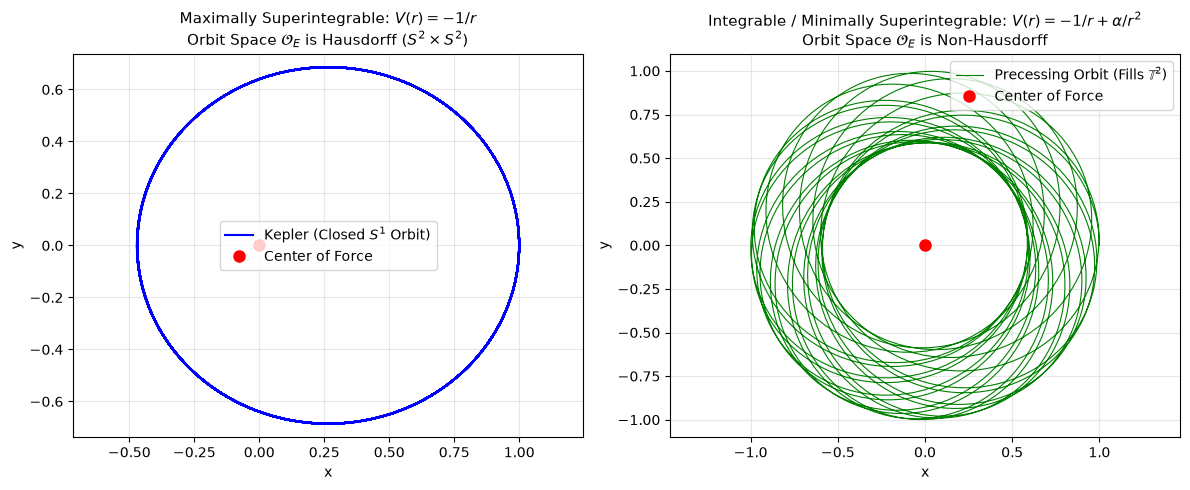

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Numerical comparison: Closed Orbit (Kepler V = -1/r) vs Precessing Orbit (V = -1/r + 0.05/r^2)
def kepler_derivatives(t, y):
    x, y_pos, vx, vy = y
    r = np.sqrt(x**2 + y_pos**2)
    ax = -x / r**3
    ay = -y_pos / r**3
    return [vx, vy, ax, ay]

def precessing_derivatives(t, y):
    x, y_pos, vx, vy = y
    r = np.sqrt(x**2 + y_pos**2)
    # V(r) = -1/r + 0.05/r^2 => F(r) = -1/r^2 + 0.1/r^3
    f_mag = -1.0/r**2 + 0.1/r**3
    ax = f_mag * (x/r)
    ay = f_mag * (y_pos/r)
    return [vx, vy, ax, ay]

# Initial conditions
y0 = [1.0, 0.0, 0.0, 0.8]
t_span = (0, 100)
t_eval = np.linspace(0, 100, 2000)

sol_kepler = solve_ivp(kepler_derivatives, t_span, y0, t_eval=t_eval, rtol=1e-9)
sol_precess = solve_ivp(precessing_derivatives, t_span, y0, t_eval=t_eval, rtol=1e-9)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Kepler Plot
axes[0].plot(sol_kepler.y[0], sol_kepler.y[1], 'b-', lw=1.5, label='Kepler (Closed $S^1$ Orbit)')
axes[0].plot(0, 0, 'ro', ms=8, label='Center of Force')
axes[0].set_title('Maximally Superintegrable: $V(r) = -1/r$\nOrbit Space $\\mathcal{O}_E$ is Hausdorff ($S^2 \\times S^2$)', fontsize=11)
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].axis('equal')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Precessing Plot
axes[1].plot(sol_precess.y[0], sol_precess.y[1], 'g-', lw=0.8, label='Precessing Orbit (Fills $\\mathbb{T}^2$)')
axes[1].plot(0, 0, 'ro', ms=8, label='Center of Force')
axes[1].set_title('Integrable / Minimally Superintegrable: $V(r) = -1/r + \\alpha/r^2$\nOrbit Space $\\mathcal{O}_E$ is Non-Hausdorff', fontsize=11)
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].axis('equal')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 6. The Infinite-Dimensional Lie Algebra of Classical Invariants

When taking mutual Poisson brackets between the vector generators $\mathbf{A}$ of $O_4$ and the 2nd-rank tensor generators $A_{jk}$ of $SU_3$, the brackets do not close into a finite Lie algebra:
$$\{A_i, A_{jk}\} = T_{ijk} \quad (3\text{rd-rank tensor invariant})$$

Iterating Poisson brackets generates higher-rank tensors $T_{i_1 i_2 \dots i_n}$ ad infinitum, embedding $O_4$ and $SU_3$ within an **infinite-dimensional Lie algebra**.

Observed Physics vs. Formal Poisson Bracket Structure:

| Aspect | Observed Physics | Formal Poisson Bracket Algebra |
| :--- | :--- | :--- |
| **Symmetry Origin** | Real closed $S^1$ orbits vs. precessing tori $\mathbb{T}^2$. | Integrability of 1D orbit equation $\theta(u)$. |
| **Functional Limit** | Strictly bounded at $2n-1 = 5$ global constants. | Infinite tensor hierarchy $T_{i_1 \dots i_k}$. |
| **Quantum Status** | Real spectral energy degeneracies ($1/r, r^2$). | Fails due to operator ordering and non-separability. |

### Physical Significance:
1. **Zero New Physical Information**: In a 3D phase space ($2n = 6$), the maximum number of functionally independent constants of motion is $2n - 1 = 5$. Every tensor in this infinite hierarchy is functionally dependent on $(\mathbf{r}, \mathbf{p})$ or $(E, \mathbf{L}, \hat{k})$.
2. **Poisson Bracket Algebraic Structure**: The infinite dimensionality is an intrinsic property of the Lie algebra of smooth functions under Poisson brackets on the phase space manifold.
3. **High-Energy Physics Motivation (1967 Context)**: Fradkin's motivation was to provide a classical constructive model embedding spacetime symmetries ($O(3,1)$) and internal symmetries ($SU_3$) into a unified infinite-dimensional structure for elementary particle physics.

---
## Quantum Mechanical Breakdown

While classical $O_4$ and $SU_3$ symmetries exist for all central potentials, they **do not** extend to quantum mechanics to generate energy degeneracies for general potentials due to:

1. **Operator Ordering & Transcendental Ambiguity**: The canonical form of $\hat{k}$ contains transcendental functions $f(u, L^2, E)$. Translating $\mathbf{p} \to -i\hbar \nabla$ leads to non-unique operator ordering, destroying self-adjointness and closed commutator algebras.
2. **Schrödinger Separability**: Commuting $O_4 / SU_3$ operators require separability in non-spherical coordinates (e.g., parabolic for Kepler, Cartesian for harmonic oscillator). Eisenhart (1948) proved general central potentials separate **only** in spherical coordinates.
3. **Spin Coupling**: Particles with spin lack independent orbital angular momentum conservation, eliminating the fixed classical orbital plane.
